In [11]:
import Noelles_proteomsim as ps

proteins = ps.read_fasta("../data/sample_proteins.fasta")
len(proteins)
proteins

{'P11802': 'MATSRYEPVAEIGVGAYGTVYKARDPHSGHFVALKSVRVPNGGGGGGGLPISTVREVALLRRLEAFEHPNVVRLMDVCATSRTDREIKVTLVFEHVDQDLRTYLDKAPPPGLPAETIKDLMRQFLRGLDFLHANCIVHRDLKPENILVTSGGTVKLADFGLARIYSYQMALTPVVVTLWYRAPEVLLQSTYATPVDMWSVGCIFAEMFRRKPLFCGNSEADQLGKIFDLIGLPPEDDWPRDVSLPRGAFPPRGPRPVQSVVPEMEESGAQLLLEMLTFNPHKRISAFRALQHSYLHKDEGNPE',
 'A0A087WTH1': 'MEDEEKAVEILGNTEAAHPPSPIRCCWLRLRCLAATSIICGCSCLGVMALVFAIKAEERHKAGRSEEAVRWGARARKLILASFAVWLAVLILGPLLLWLLSYAIAQAPEPTIDERE',
 'A0A087WTH5': 'MVIEWERPRMILSNTTAVTPFLTKLWQETVQQGGNMSGLARRSPRSGDGKLEALYVLMVLGFFGFFTLGIMLSYIRSKKLEHSNDPFNVYIESNAWQEKDKAYVQARVLESYRSCYVVENHLAIEQPNTHLPETKPSP'}

In [12]:
help(ps.digest_protein_collection)
help(ps.compute_sequence_coverage)

Help on function digest_protein_collection in module Noelles_proteomsim.protein_digestion:

digest_protein_collection(protein_map, enzyme, min_pep_len=5, max_pep_len=30)
    function that loops over every protein in the dictionary and cleaves each protein by the selected pattern and returns the resulting list of peptides and filters pwptides within a certain range.
    
    Parameters
    ----------
    protein_seq : str
        sequence of your protein
    cleave_pattern : str
        Enzyme beaviour that is mimicked
    max_pep_len : float
        the max length of each peptide
    min_pep_len
        the min length of each peptide
    Returns
    -------
    a list with all peptides that are within in the length range you put in

Help on function compute_sequence_coverage in module Noelles_proteomsim.protein_digestion:

compute_sequence_coverage(protein_seq, peptides)
    Compute the sequence coverage of a protein based on its identified peptides.
    
    The sequence coverage is c

In [13]:
seq = proteins["A0A087WTH1"]
#cleave_pattern = enzyme_cleavage_patterns['LysN']
ps.digest_protein_sequence(seq, "LysN", 5, 100)

['MEDEE',
 'KAVEILGNTEAAHPPSPIRCCWLRLRCLAATSIICGCSCLGVMALVFAI',
 'KAEERH',
 'KAGRSEEAVRWGARAR',
 'KLILASFAVWLAVLILGPLLLWLLSYAIAQAPEPTIDERE']

In [14]:
peptides_dic = ps.digest_protein_collection(proteins, "Trypsin", 5, 30)

In [15]:
ps.compute_sequence_coverage_dictionary(ps.digest_protein_collection(proteins, "Trypsin", 5, 30), proteins)

{'P11802': '0.9273927392739274',
 'A0A087WTH1': '0.5086206896551724',
 'A0A087WTH5': '0.9347826086956522'}

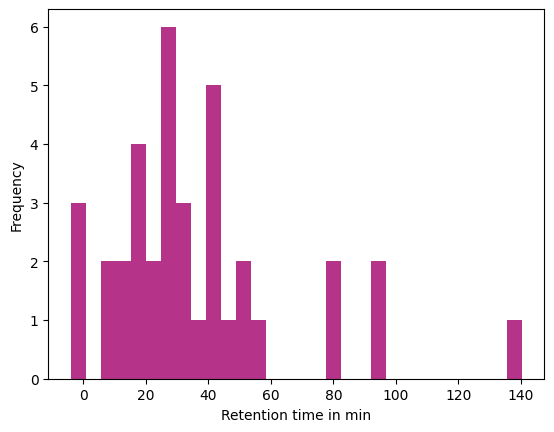

In [17]:
pooled_peptides = list([item for sublist in peptides_dic.values() for item in sublist])
rt_map = ps.predict_lc_retention_times(pooled_peptides)
ps.plot_retention_time(rt_map.values())
select_peps = ps.select_retention_time_window(rt_map, 3, 20)

In [8]:
PEPTIDE_mm = ps.calculate_mol_mass("PEPTIDE", ps.amino_acid_mass_dalton)
PEPTIDE_mm

{'PEPTIDE': 781.84}

In [21]:
peptides_mm = ps.calculate_mol_mass_collection(select_peps, ps.amino_acid_mass_dalton)
peptides_mm

{'MATSR': 546.65,
 'TYLDK': 620.71,
 'DVSLPR': 667.77,
 'GAFPPR': 625.74,
 'ISAFR': 574.69,
 'SEEAVR': 671.72,
 'AYVQAR': 688.79,
 'VLESYR': 747.8599999999999}

In [22]:
mz_peptides = ps.calculate_mz_collection(peptides_mm, 2)
mz_peptides

{'MATSR': 274.332,
 'TYLDK': 311.362,
 'DVSLPR': 334.892,
 'GAFPPR': 313.877,
 'ISAFR': 288.35200000000003,
 'SEEAVR': 336.867,
 'AYVQAR': 345.402,
 'VLESYR': 374.93699999999995}

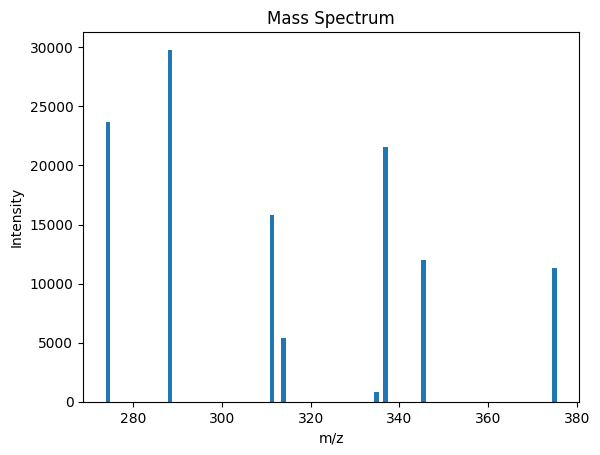

In [24]:
plot_peps_mz = ps.plot_spectrum(mz_peptides)

In [27]:
frags_pep = ps.fragment_peptide("PEPTIDE")
frags_pep

['P',
 'PE',
 'PEP',
 'PEPT',
 'PEPTI',
 'PEPTID',
 'E',
 'DE',
 'IDE',
 'TIDE',
 'PTIDE',
 'EPTIDE']